In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.datasets import load_iris
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset Iris
iris = load_iris()
X, y = iris.data, iris.target

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Definir el clasificador y los valores de los hiperparámetros a probar
clf = DecisionTreeClassifier()
param_grid = {'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, 4, 5]}

# Realizar la búsqueda de hiperparámetros utilizando GridSearchCV
grid_search = GridSearchCV(clf, param_grid=param_grid, cv=10)
grid_search.fit(X_train, y_train)

# Imprimir los resultados
print("Mejores hiperparámetros encontrados:")
print(grid_search.best_params_)
print("Mejor puntuación de validación cruzada:")
print(grid_search.best_score_)

# Modelo con parámetros optimizados
best_clf = grid_search.best_estimator_

# Predecir en el conjunto de entrenamiento y prueba
y_train_pred = best_clf.predict(X_train)
y_test_pred = best_clf.predict(X_test)

# Calcular y mostrar la matriz de confusión para el conjunto de prueba
conf_matrix_test = confusion_matrix(y_test, y_test_pred)
print("Matriz de confusión para el conjunto de prueba:")
print(conf_matrix_test)

# Calcular y mostrar la matriz de confusión para el conjunto de entrenamiento
conf_matrix_train = confusion_matrix(y_train, y_train_pred)
print("Matriz de confusión para el conjunto de entrenamiento:")
print(conf_matrix_train)


Mejores hiperparámetros encontrados:
{'criterion': 'gini', 'max_depth': 4}
Mejor puntuación de validación cruzada:
0.9254545454545455
Matriz de confusión para el conjunto de prueba:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Matriz de confusión para el conjunto de entrenamiento:
[[31  0  0]
 [ 0 37  0]
 [ 0  1 36]]


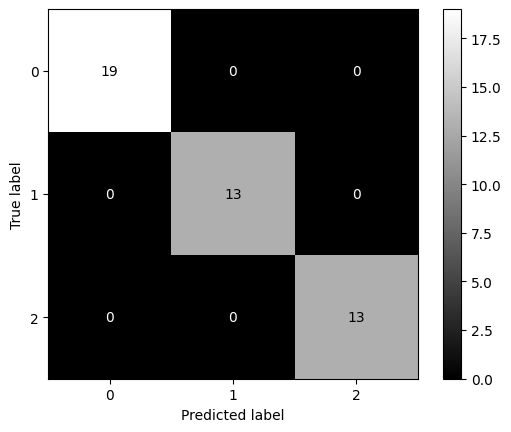

In [8]:
# Graficamos matriz de confusion
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test,y_test_pred,labels=best_clf.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_clf.classes_).plot(cmap="gray")

In [9]:
# Calculo de las predicciones en Train y test
y_train_pred = best_clf.predict(X_train)
y_test_pred = best_clf.predict(X_test)

In [10]:
from sklearn.metrics import accuracy_score
print('El accuracy en train es:',accuracy_score(y_train,y_train_pred))
print('El accuracy en test es:', accuracy_score(y_test,y_test_pred))

El accuracy en train es: 0.9714285714285714
El accuracy en test es: 1.0


In [16]:
importances = grid_search.best_estimator_.feature_importances_
importances = np.sort(importances)[::-1]

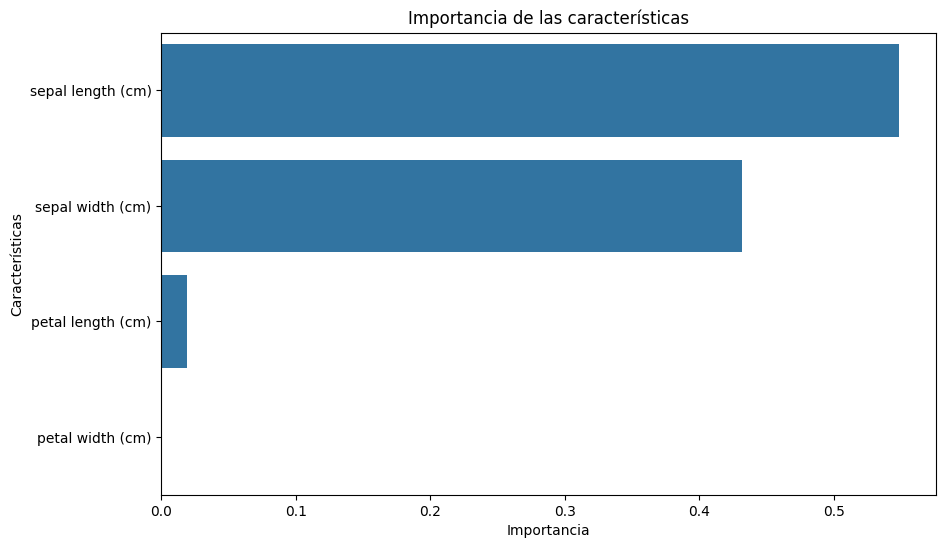

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Verificamos el feature importances
importances = grid_search.best_estimator_.feature_importances_
importances = np.sort(importances)[::-1]

# Obtenemos los nombres de las características
feature_names = iris.feature_names

# Creamos un gráfico de barras de la importancia de las características
plt.figure(figsize=(10, 6))
sns.barplot(x=importances, y=feature_names, orient='h')
plt.xlabel('Importancia')
plt.ylabel('Características')
plt.title('Importancia de las características')
plt.show()
